In [9]:
from pathlib import Path
import tensorflow as tf
import numpy as np
import pandas as pd
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from tensorflow.keras.applications.mobilenet_v2 import (
    MobileNetV2,
    preprocess_input
)

In [2]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 4

SPLIT_DATASET_PATH = Path(
    r"D:\py\Eye-Disease-Detection-system\split_dataset"
)

class_names = [
    'normal',
    'cataract',
    'conjunctivitis',
    'pterygium'
]

train_dataset = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DATASET_PATH / "train",
    labels="inferred",
    label_mode="categorical",
    class_names=class_names,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

val_dataset = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DATASET_PATH / "val",
    labels="inferred",
    label_mode="categorical",
    class_names=class_names,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DATASET_PATH / "test",
    labels="inferred",
    label_mode="categorical",
    class_names=class_names,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)


Found 2905 files belonging to 4 classes.
Found 623 files belonging to 4 classes.
Found 623 files belonging to 4 classes.


In [3]:
AUTOTUNE = tf.data.AUTOTUNE

# Improve data loading performance
train_dataset = train_dataset.prefetch(AUTOTUNE)
val_dataset = val_dataset.prefetch(AUTOTUNE)
test_dataset = test_dataset.prefetch(AUTOTUNE)

In [4]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom((-0.15, 0.10)),
    tf.keras.layers.RandomTranslation(0.05, 0.05),
    tf.keras.layers.RandomContrast(0.15),
    tf.keras.layers.RandomBrightness(0.15, value_range=(0, 255)),
], name="augmentation")


In [ ]:
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

In [10]:
# Load pretrained MobileNetV2
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
base_model.trainable = False

# Build model
inputs = tf.keras.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

# MobileNetV2 preprocessing: [0,255] -> [-1,1]
x = layers.Rescaling(
    scale=1./127.5,
    offset=-1
)(x)

# Pretrained feature extractor
x = base_model(x, training=False)

# Classification head
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    4,
    activation="softmax"
)(x)

model = tf.keras.Model(
    inputs,
    outputs,
    name="Eye_Disease_MobileNetV2"
)

model.summary()

Model: "Eye_Disease_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [11]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [12]:
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

In [13]:
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(MODEL_DIR / "best_mobilenetv2.keras"),
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

In [14]:
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=20,
    callbacks=[
        checkpoint,
        early_stopping,
        reduce_lr
    ]
)

Epoch 1/20


d:\py\Eye-Disease-Detection-system\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 294ms/step - accuracy: 0.7188 - loss: 0.7068
Epoch 1: val_accuracy improved from None to 0.84270, saving model to ..\models\best_mobilenetv2.keras

Epoch 1: finished saving model to ..\models\best_mobilenetv2.keras
91/91 ━━━━━━━━━━━━━━━━━━━━ 36s 371ms/step - accuracy: 0.7188 - loss: 0.7068 - val_accuracy: 0.8427 - val_loss: 0.5017 - learning_rate: 0.0010
Epoch 2/20
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 276ms/step - accuracy: 0.8637 - loss: 0.3835
Epoch 2: val_accuracy improved from 0.84270 to 0.88122, saving model to ..\models\best_mobilenetv2.keras

Epoch 2: finished saving model to ..\models\best_mobilenetv2.keras
91/91 ━━━━━━━━━━━━━━━━━━━━ 30s 327ms/step - accuracy: 0.8637 - loss: 0.3835 - val_accuracy: 0.8812 - val_loss: 0.4090 - learning_rate: 0.0010
Epoch 3/20
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 272ms/step - accuracy: 0.8809 - loss: 0.3191
Epoch 3: val_accuracy did not improve from 0.88122
91/91 ━━━━━━━━━━━━━━━━━━━━ 30s 325ms/step - accuracy: 0.8809 - loss: 0.3191

In [15]:
from pathlib import Path
import tensorflow as tf

MODEL_DIR = Path("../models")

# Original best transfer learning model
BEST_MODEL_PATH = MODEL_DIR / "best_mobilenetv2.keras"

# Separate fine-tuned model path
FINE_TUNED_MODEL_PATH = MODEL_DIR / "best_mobilenetv2_finetuned.keras"

# Load best Stage 1 model
model = tf.keras.models.load_model(
    str(BEST_MODEL_PATH)
)


In [17]:
base_model.trainable = True

# Freeze all layers except the last 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [18]:
fine_tune_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(MODEL_DIR / "best_mobilenetv2_finetuned.keras"),
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

fine_tune_history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=10,
    callbacks=[
        fine_tune_checkpoint,
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True
        )
    ]
)

Epoch 1/10
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 294ms/step - accuracy: 0.9466 - loss: 0.1676
Epoch 1: val_accuracy improved from None to 0.90851, saving model to ..\models\best_mobilenetv2_finetuned.keras

Epoch 1: finished saving model to ..\models\best_mobilenetv2_finetuned.keras
91/91 ━━━━━━━━━━━━━━━━━━━━ 36s 364ms/step - accuracy: 0.9466 - loss: 0.1676 - val_accuracy: 0.9085 - val_loss: 0.2744
Epoch 2/10
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 282ms/step - accuracy: 0.9446 - loss: 0.1637
Epoch 2: val_accuracy did not improve from 0.90851
91/91 ━━━━━━━━━━━━━━━━━━━━ 30s 331ms/step - accuracy: 0.9446 - loss: 0.1637 - val_accuracy: 0.9085 - val_loss: 0.2768
Epoch 3/10
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 284ms/step - accuracy: 0.9466 - loss: 0.1692
Epoch 3: val_accuracy did not improve from 0.90851
91/91 ━━━━━━━━━━━━━━━━━━━━ 30s 335ms/step - accuracy: 0.9466 - loss: 0.1692 - val_accuracy: 0.9085 - val_loss: 0.2776
Epoch 4/10
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 286ms/step - accuracy: 0.9463 - loss: 0.1652
Epoch 4: v

In [19]:
best_fine_tuned_model = tf.keras.models.load_model(
    str(FINE_TUNED_MODEL_PATH)
)

In [20]:
# Load original best model
original_model = tf.keras.models.load_model(
    str(BEST_MODEL_PATH)
)

# Evaluate original model
original_loss, original_acc = original_model.evaluate(
    val_dataset,
    verbose=0
)

# Evaluate fine-tuned model
fine_loss, fine_acc = best_fine_tuned_model.evaluate(
    val_dataset,
    verbose=0
)

print("\nMODEL COMPARISON")
print("-" * 40)

print(f"Original Model Accuracy   : {original_acc * 100:.2f}%")
print(f"Fine-Tuned Model Accuracy : {fine_acc * 100:.2f}%")

if fine_acc > original_acc:
    print("\nFine-tuning improved validation accuracy!")
else:
    print("\nOriginal model performed equally or better.")


MODEL COMPARISON
----------------------------------------
Original Model Accuracy   : 91.33%
Fine-Tuned Model Accuracy : 90.85%

Original model performed equally or better.


In [21]:
test_loss, test_accuracy = original_model.evaluate(
    test_dataset,
    verbose=1
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 216ms/step - accuracy: 0.8748 - loss: 0.3074
Test Accuracy: 87.48%
Test Loss: 0.3074


In [25]:
# Actual labels
y_true = np.concatenate([
    np.argmax(labels.numpy(), axis=1)
    for images, labels in test_dataset
])

# Model predictions
y_pred_probs = best_fine_tuned_model.predict(test_dataset)
y_pred = np.argmax(y_pred_probs, axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 243ms/step
                precision    recall  f1-score   support

        normal     0.9737    0.8409    0.9024       132
      cataract     0.9249    0.9040    0.9143       177
conjunctivitis     0.9176    0.8608    0.8883       194
     pterygium     0.7078    0.9083    0.7956       120

      accuracy                         0.8780       623
     macro avg     0.8810    0.8785    0.8752       623
  weighted avg     0.8911    0.8780    0.8808       623



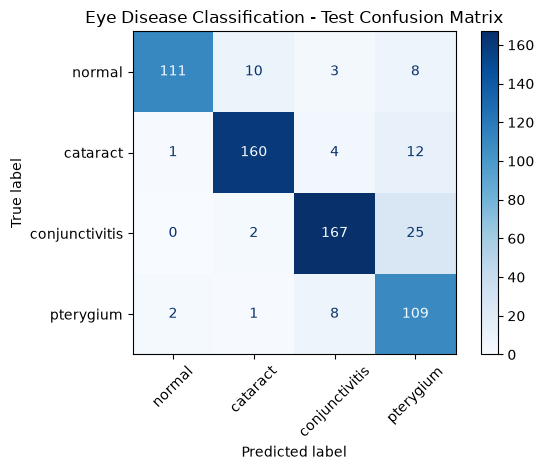

In [27]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(4)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Eye Disease Classification - Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [28]:
Path("../results").mkdir(parents=True, exist_ok=True)

results = pd.DataFrame({
    "Metric": ["Test Accuracy", "Test Loss"],
    "Value": [test_accuracy, test_loss]
})

results.to_csv("../results/experiment2_test_results.csv", index=False)

In [29]:
history_df = pd.DataFrame(history.history)

history_df.to_csv(
    "../results/mobilenetv2_history.csv",
    index=False
)

In [30]:
history_df = pd.DataFrame(fine_tune_history.history)

history_df.to_csv(
    "../results/Tuned_mobilenetv2_history.csv",
    index=False
)